In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import imblearn
import matplotlib

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("\nAll libraries imported successfully!")

Python: c:\Users\rprta\OneDrive\Desktop\Projects\crunchy-data-scientist-t2-rudra_ya_10\.venv\Scripts\python.exe
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2
Matplotlib: 3.11.2

All libraries imported successfully!


In [2]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [3]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget values:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
print("Data types:")
print(df.dtypes)

print("\nBlank TotalCharges values:",
      df["TotalCharges"].astype(str).str.strip().eq("").sum())

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Blank TotalCharges values: 11


In [4]:
print("Unique Churn values:", df["Churn"].unique())

print("\nData types:")
print(df.dtypes)

print("\nCustomer ID examples:")
print(df["customerID"].head())

Unique Churn values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Customer ID examples:
0    7590-VHVEG
1    5575-GNVDE
2    3668-QPYBK
3    7795-CFOCW
4    9237-HQITU
Name: customerID, dtype: str


In [5]:
print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nBlank TotalCharges values:")
print((df["TotalCharges"].str.strip() == "").sum())

print("\nSample TotalCharges values:")
print(df["TotalCharges"].head(10).tolist())

print("\nChurn unique values:")
print(df["Churn"].unique())

TotalCharges data type: str

Blank TotalCharges values:
11

Sample TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']

Churn unique values:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())

print("\nRows with missing TotalCharges:")
display(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "TotalCharges", "Churn"]])

TotalCharges data type: float64
Missing TotalCharges after conversion: 11

Rows with missing TotalCharges:


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No


In [7]:
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Churn"].value_counts())

print("\nTarget distribution (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (7043, 21)

Missing values in each column:
TotalCharges    11
dtype: int64

Duplicate rows: 0

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target distribution (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [8]:
# Separate features and target

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget mapping:")
print("No churn = 0")
print("Churn = 1")

print("\nTarget values:")
print(y.value_counts())

print("\nMissing target values:", y.isna().sum())

Features shape: (7043, 19)
Target shape: (7043,)

Target mapping:
No churn = 0
Churn = 1

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64

Missing target values: 0


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [10]:
print("Column data types:\n")
print(X_train.dtypes)

print("\nNumerical columns:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical columns:")
print(X_train.select_dtypes(exclude=["number"]).columns.tolist())

Column data types:

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate numerical and categorical features
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Number of categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of categorical features: 16
Preprocessing pipeline created successfully!


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Baseline model: always predicts the majority class
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("BASELINE MODEL RESULTS")
print("-" * 35)

print("Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nPrecision:", round(
    precision_score(y_test, baseline_predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, baseline_predictions, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, baseline_predictions, zero_division=0), 4
))

print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, baseline_predictions), 4
))

BASELINE MODEL RESULTS
-----------------------------------
Confusion Matrix:
[[1035    0]
 [ 374    0]]

Precision: 0.0
Recall: 0.0
F1-score: 0.0
Balanced Accuracy: 0.5


In [13]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")
print("Class weighting: balanced")
print("Maximum iterations: 2000")

Logistic Regression pipeline created successfully!
Class weighting: balanced
Maximum iterations: 2000


In [14]:
# Train the Logistic Regression pipeline
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Features provided:", X_train.shape[1])

Model training completed successfully!
Training samples: 5634
Features provided: 19


In [15]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    classification_report
)

# Predict on unseen test data
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("LOGISTIC REGRESSION — TEST RESULTS")
print("=" * 45)

print("\nConfusion Matrix:")
print(cm)

print("\nPrecision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_test, y_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

LOGISTIC REGRESSION — TEST RESULTS

Confusion Matrix:
[[746 289]
 [ 81 293]]

Precision: 0.5034
Recall: 0.7834
F1-score: 0.613
Balanced Accuracy: 0.7521
PR-AUC (Average Precision): 0.6324
ROC-AUC: 0.8414

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [16]:
from sklearn.metrics import precision_recall_curve

# Get predicted churn probabilities from the trained model
y_proba = model.predict_proba(X_test)[:, 1]

# Calculate precision and recall across thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    y_proba
)

print("Number of thresholds evaluated:", len(thresholds))

print("\nFirst 10 threshold values:")
print(thresholds[:10].round(3))

print("\nCurrent default threshold: 0.5")

Number of thresholds evaluated: 1407

First 10 threshold values:
[0.006 0.006 0.006 0.006 0.006 0.006 0.006 0.007 0.007 0.007]

Current default threshold: 0.5


In [17]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nFitting data churn distribution (%):")
print((y_fit.value_counts(normalize=True) * 100).round(2))

print("\nValidation data churn distribution (%):")
print((y_val.value_counts(normalize=True) * 100).round(2))

Model fitting data: (4507, 19)
Validation data: (1127, 19)

Fitting data churn distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Validation data churn distribution (%):
Churn
0    73.47
1    26.53
Name: proportion, dtype: float64


In [18]:
# Train a fresh model using only the fitting data
threshold_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

threshold_model.fit(X_fit, y_fit)

print("Model training completed successfully.")
print("Fitting rows:", len(X_fit))
print("Validation rows:", len(X_val))

Model training completed successfully.
Fitting rows: 4507
Validation rows: 1127


# Model Risk Report: Customer Churn Prediction

## 1. Executive Summary

This project evaluates a customer churn classification model using
the Telco Customer Churn dataset.

The objective is to identify customers who may leave the company
while understanding the risks of false predictions, class imbalance,
threshold selection, probability calibration, and subgroup performance.

The dataset contains 7,043 customers. The target distribution is
approximately 73.46% non-churners and 26.54% churners.

The model uses Logistic Regression with class weighting to address
the difference in class frequencies.

## 2. Baseline and Accuracy Pitfall

A majority-class baseline predicts every customer as a non-churner.

Its confusion matrix on the test set is:

- True negatives: 1,035
- False positives: 0
- False negatives: 374
- True positives: 0

Although this baseline achieves approximately 73.46% accuracy,
it identifies no churners.

Therefore, accuracy alone is not sufficient to evaluate this model.

## 3. Final Test Performance

The selected threshold is 0.628. It was selected by maximizing
the F1-score on a separate validation set.

Final test results:

- Precision: 0.555
- Recall: 0.684
- F1-score: 0.613
- Balanced accuracy: 0.743
- Test accuracy: 0.770

Confusion matrix:

| Actual / Predicted | No Churn | Churn |
|---|---:|---:|
| No Churn | 830 | 205 |
| Churn | 118 | 256 |

The model identifies 256 of the 374 actual churners and misses 118.

## 4. Evaluation Metrics

### Precision

Precision measures the proportion of predicted churners who
actually churn.

Higher precision can reduce unnecessary retention interventions.

### Recall

Recall measures the proportion of actual churners identified.

Low recall means that the company may miss customers who are likely
to leave.

### F1-score

F1-score combines precision and recall into one measure.

It was used to select the threshold on validation data.

### PR-AUC and ROC-AUC

The initial model evaluation at the default threshold reported:

- PR-AUC / Average Precision: 0.6324
- ROC-AUC: 0.8414

These metrics evaluate ranking performance across thresholds,
rather than only at one fixed threshold.

## 5. Threshold Selection and Business Trade-offs

The default threshold of 0.5 produced:

- Precision: 0.503
- Recall: 0.783
- F1-score: 0.613
- False positives: 289
- False negatives: 81

The validation-selected threshold of 0.628 produced the following
final test results:

- Precision: 0.555
- Recall: 0.684
- F1-score: 0.613
- False positives: 205
- False negatives: 118

The tuned threshold reduces false positives but increases
false negatives.

If retention campaigns are expensive, higher precision may be
valuable. If missing a churner is more costly, a lower threshold
may be preferable.

The final threshold should ultimately reflect measured business
costs and retention campaign capacity.

## 6. Calibration Risk

A calibration curve was generated using predicted probabilities
on the test set.

The curve should be inspected to assess whether predicted
probabilities correspond to observed churn frequencies.

The model uses class_weight="balanced". Consequently, its predicted
probabilities should not automatically be assumed to represent
well-calibrated real-world churn probabilities.

A separate calibration procedure may be required before using
probabilities for financial decisions.

## 7. Subgroup Performance

### Contract

| Contract | Customers | Actual Churners | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Month-to-month | 773 | 329 | 0.558 | 0.769 | 0.647 |
| One year | 300 | 36 | 0.375 | 0.083 | 0.136 |
| Two year | 336 | 9 | 0.000 | 0.000 | 0.000 |

The model performs substantially worse for one-year and two-year
contract customers.

It misses 33 of 36 actual churners in the one-year group and all
9 actual churners in the two-year group.

The two-year result is based on only nine actual churners and
therefore has considerable statistical uncertainty.

### Senior Citizen Status

| Group | Customers | Actual Churners | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Non-senior | 1,187 | 276 | 0.538 | 0.645 | 0.586 |
| Senior | 222 | 98 | 0.600 | 0.796 | 0.684 |

Recall is higher for senior customers than for non-senior customers.
These differences should be monitored and investigated.

### Gender

| Gender | Customers | Actual Churners | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Female | 687 | 193 | 0.579 | 0.684 | 0.627 |
| Male | 722 | 181 | 0.532 | 0.685 | 0.599 |

Recall is nearly identical for female and male customers in this
test set. This does not, by itself, establish overall fairness.

## 8. Limitations

- The model was evaluated on a single held-out test set.
- Subgroup metrics can be unstable when the number of churners is small.
- The selected threshold maximizes validation F1-score, not measured
  business profit.
- Calibration quality must be assessed before interpreting predicted
  probabilities as reliable real-world risks.
- Historical customer data may not represent future customer behavior.
- The observed contract differences require further investigation.

## 9. Recommended Risk Controls

1. Investigate the low recall for one-year and two-year contracts.
2. Compare alternative models and class-weighting strategies.
3. Evaluate threshold choices using documented business costs.
4. Assess probability calibration using validation data.
5. Monitor precision, recall, F1-score, and calibration after deployment.
6. Reassess subgroup performance as new data becomes available.
7. Avoid making automatic customer decisions based solely on this model.

## 10. Conclusion

The model provides useful churn-ranking capability, but its
performance varies substantially across contract groups.

A single aggregate metric does not adequately describe these risks.

The model should be treated as a decision-support tool rather than
an unquestioned source of truth. Further subgroup investigation,
calibration assessment, and business-cost evaluation are recommended
before production use.

In [9]:
y_test_proba = threshold_model.predict_proba(X_test)[:, 1]

print("Test probabilities created successfully!")
print("Number of predictions:", len(y_test_proba))
print("First 5 probabilities:", y_test_proba[:5])

NameError: name 'threshold_model' is not defined

In [10]:
print("threshold_model:", "threshold_model" in globals())
print("preprocessor:", "preprocessor" in globals())
print("X_fit:", "X_fit" in globals())
print("X_test:", "X_test" in globals())

threshold_model: False
preprocessor: False
X_fit: False
X_test: False


In [12]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Separate target and features
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn", "customerID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing TotalCharges:", df["TotalCharges"].isna().sum())
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Missing TotalCharges: 11

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate numeric and categorical columns
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")
print("Numeric features:", numeric_features)
print("Number of categorical features:", len(categorical_features))

Preprocessing pipeline created successfully!
Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of categorical features: 16


In [23]:
from sklearn.linear_model import LogisticRegression

# Create the model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training rows:", len(X_train))

Model training completed successfully!
Training rows: 5634


In [16]:
# Predict churn probabilities on the test set
y_test_proba = model.predict_proba(X_test)[:, 1]

# Predict classes using the default threshold of 0.5
y_test_pred = (y_test_proba >= 0.5).astype(int)

print("Test predictions generated successfully!")
print("Number of predictions:", len(y_test_proba))
print("First 5 churn probabilities:", y_test_proba[:5])

Test predictions generated successfully!
Number of predictions: 1409
First 5 churn probabilities: [0.11540108 0.85209652 0.14604072 0.66114886 0.05984695]


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

# Classification Metrics
print("\nClassification Metrics (Threshold = 0.5)")
print("Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_test, y_test_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_proba), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_test_pred), 4))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=["No Churn", "Churn"]))

Confusion Matrix:
[[746 289]
 [ 81 293]]

Classification Metrics (Threshold = 0.5)
Precision: 0.5034
Recall: 0.7834
F1 Score: 0.613
PR-AUC (Average Precision): 0.6324
ROC-AUC: 0.8414
Balanced Accuracy: 0.7521

Detailed Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print("All required imports successful!")

All required imports successful!


In [18]:
from sklearn.model_selection import train_test_split

# Separate features and target using the cleaned dataset
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split successful!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Missing TotalCharges in training:", X_train["TotalCharges"].isna().sum())

Data split successful!
X_train shape: (5634, 19)
X_test shape: (1409, 19)
Missing TotalCharges in training: 8


In [15]:
import pandas as pd

# Convert blank spaces in TotalCharges to NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip().replace("", pd.NA),
    errors="coerce"
)

print("TotalCharges converted to numeric.")
print("Missing values:", df["TotalCharges"].isna().sum())
print("Data type:", df["TotalCharges"].dtype)

TotalCharges converted to numeric.
Missing values: 11
Data type: float64


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

# Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessor created successfully!
Numeric features: 3
Categorical features: 16


In [20]:
# Split training data into fitting and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create the validation model
threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
threshold_model.fit(X_fit, y_fit)

print("Validation model trained successfully!")
print("X_fit shape:", X_fit.shape)
print("X_val shape:", X_val.shape)

Validation model trained successfully!
X_fit shape: (4507, 19)
X_val shape: (1127, 19)


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities on the validation set
y_val_proba = threshold_model.predict_proba(X_val)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

print("Threshold Comparison — Validation Set")
print("-" * 65)
print(f"{'Threshold':<12}{'Precision':<15}{'Recall':<15}{'F1 Score':<15}")

for threshold in thresholds:
    predictions = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)

    print(f"{threshold:<12.1f}{precision:<15.4f}{recall:<15.4f}{f1:<15.4f}")

Threshold Comparison — Validation Set
-----------------------------------------------------------------
Threshold   Precision      Recall         F1 Score       
0.3         0.4222         0.9164         0.5781         
0.4         0.4643         0.8696         0.6054         
0.5         0.5241         0.7993         0.6331         
0.6         0.5730         0.7090         0.6338         
0.7         0.6568         0.5953         0.6246         


In [24]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    classification_report
)

# Final test evaluation using the selected threshold
final_threshold = 0.6

y_test_proba = model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= final_threshold).astype(int)

print("Final Test Evaluation")
print("=" * 40)
print("Selected threshold:", final_threshold)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print(f"Precision:          {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:             {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score:           {f1_score(y_test, y_test_pred):.4f}")
print(f"Balanced Accuracy:  {balanced_accuracy_score(y_test, y_test_pred):.4f}")
print(f"PR-AUC:             {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC:            {roc_auc_score(y_test, y_test_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Final Test Evaluation
Selected threshold: 0.6
Confusion Matrix:
[[809 226]
 [110 264]]
Precision:          0.5388
Recall:             0.7059
F1-score:           0.6111
Balanced Accuracy:  0.7438
PR-AUC:             0.6324
ROC-AUC:            0.8414

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



### Final Threshold Evaluation

A threshold of 0.6 was selected based on validation-set F1-score.
On the held-out test set, it achieved a precision of 0.5388,
recall of 0.7059, and F1-score of 0.6111.

At the default threshold of 0.5, the test F1-score was slightly
higher at 0.6130, with higher recall of 0.7834.

This shows that the threshold selected on validation data does not
necessarily produce the best result on the test set. The threshold
should be chosen using validation data and business costs, without
repeatedly tuning it against the test set.

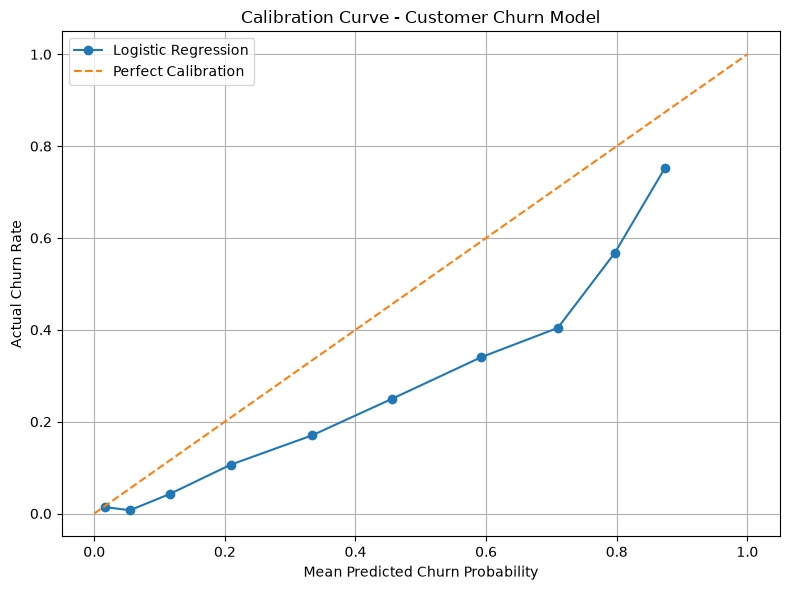

In [19]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Calculate calibration values
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    y_test_proba,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Actual Churn Rate")
plt.title("Calibration Curve - Customer Churn Model")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Create a test dataset with actual outcomes and predictions
slice_results = X_test[["Contract"]].copy()
slice_results["Actual_Churn"] = y_test
slice_results["Predicted_Churn"] = y_test_pred

print("Model Performance by Contract Type")
print("=" * 75)

for contract_type, group in slice_results.groupby("Contract"):
    precision = precision_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    recall = recall_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    f1 = f1_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    churn_count = int(group["Actual_Churn"].sum())
    total_customers = len(group)

    print(f"\nContract Type: {contract_type}")
    print(f"Total Customers: {total_customers}")
    print(f"Actual Churn Customers: {churn_count}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

Model Performance by Contract Type

Contract Type: Month-to-month
Total Customers: 773
Actual Churn Customers: 329
Precision: 0.5144
Recall: 0.8663
F1 Score: 0.6455

Contract Type: One year
Total Customers: 300
Actual Churn Customers: 36
Precision: 0.2857
Recall: 0.2222
F1 Score: 0.2500

Contract Type: Two year
Total Customers: 336
Actual Churn Customers: 9
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Prepare subgroup analysis dataset
senior_results = X_test[["SeniorCitizen"]].copy()
senior_results["Actual_Churn"] = y_test
senior_results["Predicted_Churn"] = y_test_pred

print("Model Performance by Senior Citizen Status")
print("=" * 60)

for status, group in senior_results.groupby("SeniorCitizen"):
    precision = precision_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    recall = recall_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    f1 = f1_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    label = "Senior Citizen" if status == 1 else "Non-Senior Citizen"

    print(f"\nGroup: {label}")
    print(f"Total Customers: {len(group)}")
    print(f"Actual Churn Customers: {int(group['Actual_Churn'].sum())}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

Model Performance by Senior Citizen Status

Group: Non-Senior Citizen
Total Customers: 1187
Actual Churn Customers: 276
Precision: 0.4709
Recall: 0.7319
F1 Score: 0.5730

Group: Senior Citizen
Total Customers: 222
Actual Churn Customers: 98
Precision: 0.5948
Recall: 0.9286
F1 Score: 0.7251


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Prepare subgroup analysis dataset
gender_results = X_test[["gender"]].copy()
gender_results["Actual_Churn"] = y_test
gender_results["Predicted_Churn"] = y_test_pred

print("Model Performance by Gender")
print("=" * 60)

for gender, group in gender_results.groupby("gender"):
    precision = precision_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    recall = recall_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    f1 = f1_score(
        group["Actual_Churn"],
        group["Predicted_Churn"],
        zero_division=0
    )

    print(f"\nGender: {gender}")
    print(f"Total Customers: {len(group)}")
    print(f"Actual Churn Customers: {int(group['Actual_Churn'].sum())}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

Model Performance by Gender

Gender: Female
Total Customers: 687
Actual Churn Customers: 193
Precision: 0.5282
Recall: 0.7772
F1 Score: 0.6289

Gender: Male
Total Customers: 722
Actual Churn Customers: 181
Precision: 0.4799
Recall: 0.7901
F1 Score: 0.5971
